# Part 1b _Fluid dynamics_ waves

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2
from ipywidgets import interact, FloatSlider

In [ ]:
# Define the parameters
Hs = 8
Tp = 10
gamma = 3.3
fp = 1 / Tp

0.1


# Pierson–Moskowitz and JONSWAP spectra

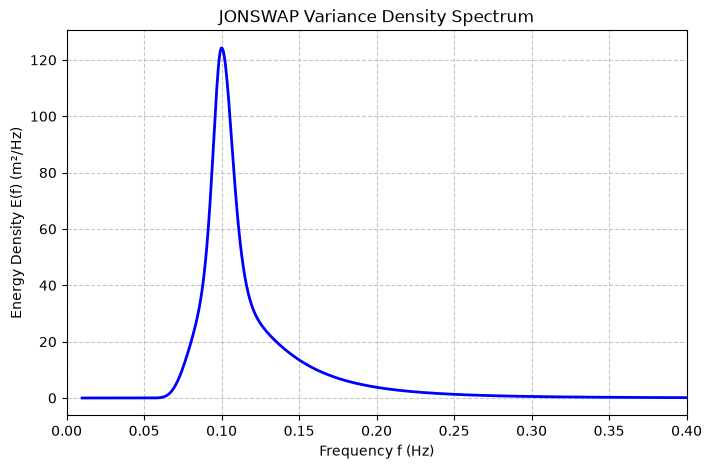

In [72]:
f = np.linspace(0.01, 0.5, 1000)
A_gamma = 1 - 0.287 * np.log(gamma)

# Calculate sigma (width parameter) based on frequency
sigma = np.zeros_like(f) 
for i in range(len(f)):
    if f[i] <= fp:
        sigma[i] = 0.07
    else:
        sigma[i] = 0.09

# --- Calculate Pierson–Moskowitz (PM) ---
E_PM = (5/16) * ((Hs)**2) * ((fp)**4) * ((f)**-5) * np.exp(-1.25 * ((fp / f)**4))

# --- Calculate the JONSWAP Peak ---
exponent = -((f - fp)**2) / (2 * (sigma**2) * (fp**2))
gamma_enhancement = gamma ** np.exp(exponent)

# --- Calculate the Final JONSWAP Spectrum E(f) ---
E_f = A_gamma * E_PM * gamma_enhancement

# --- Plot the Spectrum ---
plt.figure(figsize=(8, 5))
plt.plot(f, E_f, color='blue', linewidth=2)

# Formatting the plot
plt.title('JONSWAP Variance Density Spectrum')
plt.xlabel('Frequency f (Hz)')
plt.ylabel('Energy Density E(f) (m²/Hz)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim(0, 0.4) 
plt.show()

# Determine 𝑇𝑚0, 𝑇𝑚02, and 𝑇𝑚-10

In [ ]:
# Calculate the spectral moments using numerical integration
m_minus1 = np.trapezoid(E_f * (f**-1), f)   # -1st moment
m0 = np.trapezoid(E_f, f)                   # 0th moment (Area under curve)
m1 = np.trapezoid(E_f * f, f)               # 1st moment
m2 = np.trapezoid(E_f * (f**2), f)          # 2nd moment

# Calculate the periods
Tm01 = m0 / m1
Tm02 = np.sqrt(m0 / m2)  
Tm_minus10 = m_minus1 / m0

# Print the results 
print(f"Tm01 (Mean Period) = {Tm01:.2f} seconds")
print(f"Tm02 (Rice 'influenced by choppy, fast little waves') = {Tm02:.2f} seconds")
print(f"Tm-10 Energy Period(Power, run-up, overtopping) = {Tm_minus10:.2f} seconds")

comparison 4.004411362831888
Tm01 (Mean Period) = 8.39 seconds
Tm02 (Rice 'influenced by choppy, fast little waves') = 7.93 seconds
Tm-10 Energy Period(Power, run-up, overtopping) = 9.04 seconds


# Calculate wave steepness

In [69]:
lambda_P = 9.81 * (Tp**2) / (2 * np.pi)
k = (2 * np.pi) / lambda_P
a = Hs / 2
ka = k * a
steepness = Hs / lambda_P
print(f"Wave steepness = {steepness:.4f} m")

Wave steepness = 0.0512 m
